### define global variables

In [1]:
model_order = [
    "Cohere CAT+",
    "Command A+",
    "CUNI-EdUKate",
    "CUNI-MH-v3",
    "DeepSeek V4 Pro",
    "Dubformer",
    "Gemini 3.1 Pro",
    "Gemma 4 - 4B",
    "Gemma 4 - 31B",
    "GLM 4 - 9B",
    "GoogleTranslate",
    "GPT 5.5",
    "GPT OSS 20B",
    "GPT OSS 120B",
    "Ministral 3 - 14B",
    "Mistral Medium 3.5",
    "Qingqiu-MT-9B",
    "Qwen 3.5 - 9b",
    "Qwen 3.6 - 27b",
    "SalamandraTA",
    "Tiny Aya Global",
    "Tower 9B",
    "TRIVE",
    "UvA-MT",
]

In [2]:
import pandas as pd 

# import original test set
var_testset = pd.read_csv("../df_var.tsv", sep ="\t")


# get term matches (list of binary matches) for the target term
var_matches = pd.read_csv(
    "./wmt_json_translations/results/var/tgt_term_gold.csv",
    sep=",",
    encoding="utf-8-sig"
)

cols = model_order
var_matches = var_matches[cols]

var_matches_list = var_matches.map(lambda x: 0 if str(x).strip() in ["[]", "", "nan"] else 1)

# get term matches (list of binary matches) for the cumulated distractors
# Load the three distractor match files
# Cumulated distractor match:
# 1 if there is at least one match in AT, DE, or CH
# 0 otherwise
var_matches_AT = pd.read_csv(
    "./wmt_json_translations/results/var/tgt_term_AT.csv",
    sep=",",
    encoding="utf-8-sig"
)[cols]

var_matches_DE = pd.read_csv(
    "./wmt_json_translations/results/var/tgt_term_DE.csv",
    sep=",",
    encoding="utf-8-sig"
)[cols]

var_matches_CH = pd.read_csv(
    "./wmt_json_translations/results/var/tgt_term_CH.csv",
    sep=",",
    encoding="utf-8-sig"
)[cols]


var_matches_AT_bin = var_matches_AT.map(
    lambda x: 0 if str(x).strip() in ["[]", "", "nan"] else 1
)

var_matches_DE_bin = var_matches_DE.map(
    lambda x: 0 if str(x).strip() in ["[]", "", "nan"] else 1
)

var_matches_CH_bin = var_matches_CH.map(
    lambda x: 0 if str(x).strip() in ["[]", "", "nan"] else 1
)


var_distractors_matches_list = (
    (var_matches_AT_bin + var_matches_DE_bin + var_matches_CH_bin) > 0
).astype(int)


# import frequencies as a row list
# get term matches
freq_count = pd.read_csv("./freq_counts/count_var.csv")


freq_count_list = freq_count["total"]


In [3]:
cols

['Cohere CAT+',
 'Command A+',
 'CUNI-EdUKate',
 'CUNI-MH-v3',
 'DeepSeek V4 Pro',
 'Dubformer',
 'Gemini 3.1 Pro',
 'Gemma 4 - 4B',
 'Gemma 4 - 31B',
 'GLM 4 - 9B',
 'GoogleTranslate',
 'GPT 5.5',
 'GPT OSS 20B',
 'GPT OSS 120B',
 'Ministral 3 - 14B',
 'Mistral Medium 3.5',
 'Qingqiu-MT-9B',
 'Qwen 3.5 - 9b',
 'Qwen 3.6 - 27b',
 'SalamandraTA',
 'Tiny Aya Global',
 'Tower 9B',
 'TRIVE',
 'UvA-MT']

In [4]:
#upload training history and save in a variable
import csv

results_var = pd.read_csv("./wmt_json_translations/results/term_accuracy_rates_var.tsv", sep="\t")
results_var.columns = results_var.columns.str.strip()
results_var["model"] = results_var["model"].astype(str).str.strip()

# Filter and reorder to match cols
results = results_var[results_var["model"].isin(cols)].copy()
results["model"] = pd.Categorical(results["model"], categories=cols, ordered=True)
results = results.sort_values("model").reset_index(drop=True)


In [5]:
#import translations

from pathlib import Path

hypotheses_dir='./wmt_json_translations/translations/var',

translations_folder_var = Path(
    "./wmt_json_translations/translations/var"
)

# Read every .txt file in the folder
translation_columns = {}

for txt_file in sorted(translations_folder_var.glob("*.txt")):
    model_name = txt_file.stem

    with open(txt_file, "r", encoding="utf-8") as f:
        translations = [line.rstrip("\n") for line in f]

    translation_columns[model_name] = translations


# Check that all models have the same number of translations
lengths = {
    model: len(translations)
    for model, translations in translation_columns.items()
}

if len(set(lengths.values())) != 1:
    raise ValueError(
        f"Translation files have different numbers of rows: {lengths}"
    )


# Create dataframe:
# columns = models
# rows = hypothesis translations
hyp_translations_var = pd.DataFrame(translation_columns)

#hyp_translations_var

# Validate parallel and synthetic contexts performances

In [6]:
def compare_parallel_contexts(var_testset, var_matches_list):
    """
    Compare model performance between synthetic and parallel contexts.

    The function identifies paired instance_ids using in the test set, where human parallel
    examples are marked with the `_par` suffix. It then separates synthetic
    and parallel rows, aligns them by their shared base ID, and calculates
    the percentage of positive matches for each model in both sets.

    Parameters
    ----------
    var_testset : pandas.DataFrame
        Eurac Test set.

    var_matches_list : pandas.DataFrame
        Table with term matches (derived from term_finder pipeline). Rows are testset instances, columns are models
        Matches are 1, non matches are 0

    Returns
    -------
    pandas.DataFrame
        A table with one row per model and columns:
        `model`, `synthetic`, and `parallel` contexts.
    """

    # Copies
    var_testset_op = var_testset.copy()
    var_matches_list_op = var_matches_list.copy()

    # Attach IDs to result table, assuming rows are in the same order as var_testset
    var_matches_list_op["instance_id"] = var_testset_op["instance_id"].values

    # Create base ID and parallel flag
    var_testset_op["base_id"] = var_testset_op["instance_id"].str.replace(
        r"_par$", "", regex=True
    )
    var_testset_op["is_par"] = var_testset_op["instance_id"].str.endswith("_par")

    # Keep only IDs that have both base and _par versions
    paired_base_ids = (
        var_testset_op
        .groupby("base_id")["is_par"]
        .nunique()
    )

    paired_base_ids = paired_base_ids[paired_base_ids == 2].index

    paired_map = var_testset_op[
        var_testset_op["base_id"].isin(paired_base_ids)
    ][["instance_id", "base_id", "is_par"]]

    # Add base_id and is_par to result table
    all_par_results = var_matches_list_op.merge(
        paired_map,
        on="instance_id",
        how="inner"
    )

    # Identify model columns
    metadata_cols = {"instance_id", "base_id", "is_par"}
    model_cols = [c for c in all_par_results.columns if c not in metadata_cols]

    # Synthetic / non-parallel rows
    non_par_results = (
        all_par_results[all_par_results["is_par"] == False]
        .set_index("base_id")[model_cols]
        .sort_index()
    )

    # Parallel rows
    par_results = (
        all_par_results[all_par_results["is_par"] == True]
        .set_index("base_id")[model_cols]
        .sort_index()
    )

    # Align both tables by shared base_id
    common_ids = non_par_results.index.intersection(par_results.index)

    non_par_aligned = non_par_results.loc[common_ids]
    par_aligned = par_results.loc[common_ids]
    #print(par_aligned)
    
    
    # Percentage of 1s for each model in each table
    final_results = pd.DataFrame({
        "synthetic": non_par_aligned.mean() * 100,
        "parallel": par_aligned.mean() * 100
    })

    # Models as rows
    final_results = final_results.reset_index()
    final_results.columns = ["model", "synthetic", "parallel"]

    return final_results

import matplotlib.pyplot as plt
import numpy as np


def plot_parallel_context_results(results, figsize=(12, 6)):
    """
    Plot synthetic vs. parallel context match success percentages by model.

    Parameters
    ----------
    results : pandas.DataFrame
        Output of compare_parallel_contexts(), with columns:
        'model', 'synthetic', and 'parallel'.

    figsize : tuple, optional
        Figure size.

    Returns
    -------
    fig, ax
        Matplotlib figure and axes objects.
    """

    x = np.arange(len(results))

    fig, ax = plt.subplots(figsize=figsize)

    # Vertical line connecting the two scores for each model
    for i in x:
        ax.plot(
            [i, i],
            [results.loc[i, "synthetic"], results.loc[i, "parallel"]],
            color="gray",
            linewidth=1.5,
            alpha=0.7,
            zorder=1
        )

    # Synthetic-context points
    ax.scatter(
        x,
        results["synthetic"],
        marker="o",
        color="tab:blue",
        s=70,
        label="Synthetic source",
        zorder=2
    )

    # Parallel-context points
    ax.scatter(
        x,
        results["parallel"],
        marker="D",
        color="tab:orange",
        s=70,
        label="Parallel source",
        zorder=2
    )

    ax.set_xticks(x)
    ax.set_xticklabels(results["model"], rotation=45, ha="right")

    ax.set_ylabel("Term accuracy")
    ax.set_xlabel("Model")
    ax.set_ylim(0, 100)

    ax.legend()
    ax.grid(axis="y", linestyle="--", alpha=0.3)

    fig.tight_layout()

    return fig, ax

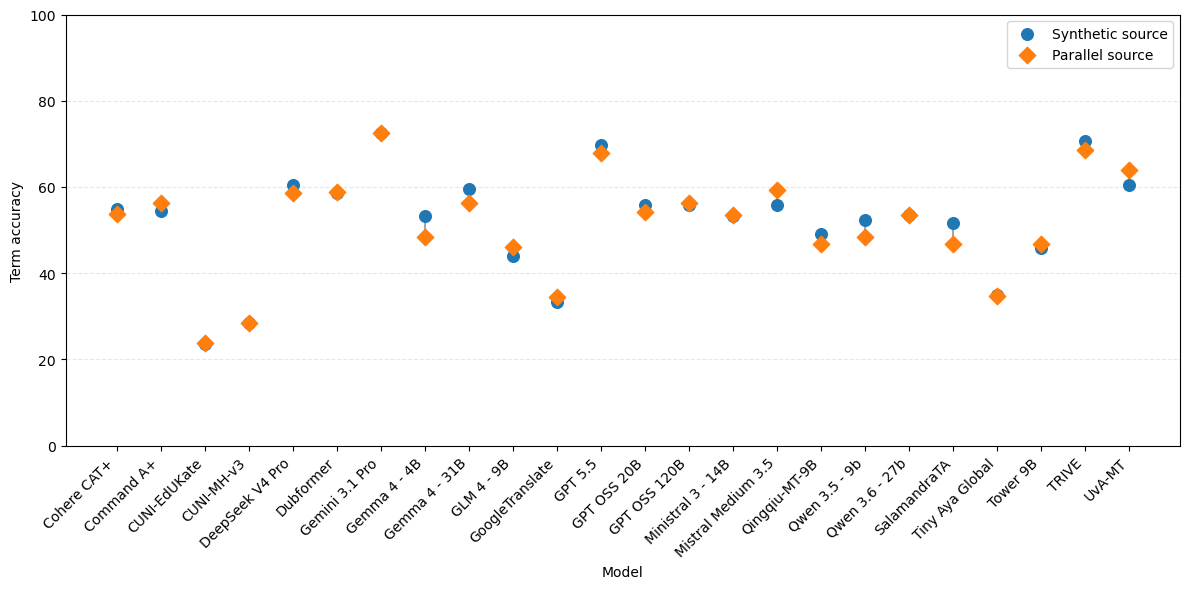

In [7]:
par_synth_results = compare_parallel_contexts(
    var_testset=var_testset,
    var_matches_list=var_matches_list
)

par_synth_results = par_synth_results.set_index("model").loc[model_order].reset_index()

fig, ax = plot_parallel_context_results(par_synth_results)
#plt.show()

In [8]:
fig.savefig("./results_tables_and_plots/1_synth_validation_ta_var.png", dpi=300, bbox_inches="tight")

In [9]:
par_synth_results.to_csv("./results_tables_and_plots/1_synth_validation_ta_var.tsv", sep="\t", index=False)
par_synth_results

,model,synthetic,parallel
0,Cohere CAT+,54.777070,53.821656
1,Command A+,54.458599,56.369427
2,CUNI-EdUKate,23.566879,23.885350
3,CUNI-MH-v3,28.343949,28.343949
4,DeepSeek V4 Pro,60.509554,58.598726
5,Dubformer,58.598726,58.917197
6,Gemini 3.1 Pro,72.611465,72.611465
7,Gemma 4 - 4B,53.184713,48.407643
8,Gemma 4 - 31B,59.554140,56.369427
9,GLM 4 - 9B,43.949045,46.178344


### first result table: comparison of performances btw human and synthetic sources per model

### aggregated results in a table/plot

# Separate par and synth contexts

In [10]:
# Find rows in var_testset where instance_id ends with "_par"
par_idx = var_testset.index[
    var_testset["instance_id"].str.endswith("_par", na=False)
]

# Original var_testset without _par rows
var_testset_synth = var_testset.drop(index=par_idx).copy()

# New dataframe with only _par rows
var_testset_par = var_testset.loc[par_idx].copy()

# Apply the same split to other aligned variables
var_matches_list_par = var_matches_list.loc[par_idx].copy()
var_matches_list_synth = var_matches_list.drop(index=par_idx).copy()

# Apply the same split to distractor matches
var_distractors_matches_list_par = var_distractors_matches_list.loc[par_idx].copy()
var_distractors_matches_list_synth = var_distractors_matches_list.drop(index=par_idx).copy()


freq_count_list_par = freq_count_list.loc[par_idx].copy()
freq_count_list = freq_count_list.drop(index=par_idx).copy()

hyp_translations_var_par = hyp_translations_var.loc[par_idx].copy()
hyp_translations_var_synth = hyp_translations_var.drop(index=par_idx).copy()

var_matches_CH_synth = var_matches_CH.drop(index=par_idx).copy()
var_matches_AT_synth = var_matches_AT.drop(index=par_idx).copy()
var_matches_DE_synth = var_matches_DE.drop(index=par_idx).copy()


In [12]:
len(var_testset_synth)

1662

# Plot term accuracy, bleu and chrf

### term accuracy

In [11]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np


def plot_term_accuracy(var_matches_list, var_distractors_matches_list,
                       figsize=(12, 6)):
    """
    Plot cumulative distractor match rate and final term accuracy
    for each model.

    Final term accuracy:
        target match = 1 AND distractor match = 0

    Parameters
    ----------
    var_matches_list : pandas.DataFrame
        Binary target-term matches.
        Rows are test-set instances and columns are models.

    var_distractors_matches_list : pandas.DataFrame
        Binary cumulative distractor matches.
        1 = at least one distractor matched
        0 = no distractor matched.

    figsize : tuple, optional
        Figure size.

    Returns
    -------
    fig, ax : matplotlib Figure and Axes

    accuracy_df : pandas.DataFrame
        Table containing model, term accuracy,
        and cumulative distractor match rate.
    """

    # Align rows and models
    common_index = var_matches_list.index.intersection(
        var_distractors_matches_list.index
    )

    common_cols = var_matches_list.columns.intersection(
        var_distractors_matches_list.columns
    )

    target = var_matches_list.loc[common_index, common_cols]
    distractor = var_distractors_matches_list.loc[
        common_index, common_cols
    ]

    # Percentage of examples containing at least one distractor match
    distractor_rate = distractor.mean() * 100

    # Correct target AND no distractor
    term_accuracy = (
        (target == 1) & (distractor == 0)
    ).mean() * 100

    # Results dataframe
    accuracy_df = pd.DataFrame({
        "model": common_cols,
        "term_accuracy": term_accuracy.values,
        "distractor_match_rate": distractor_rate.values
    })

    x = np.arange(len(accuracy_df))

    fig, ax = plt.subplots(figsize=figsize)

    # Vertical line connecting both values for every model
    for i in x:
        ax.plot(
            [i, i],
            [
                accuracy_df.loc[i, "distractor_match_rate"],
                accuracy_df.loc[i, "term_accuracy"]
            ],
            color="gray",
            linewidth=1.5,
            alpha=0.7,
            zorder=1
        )

    # Term accuracy
    ax.scatter(
        x,
        accuracy_df["term_accuracy"],
        marker="o",
        color="green",
        s=70,
        label="Term accuracy",
        zorder=2
    )

    # Cumulative distractor match rate
    ax.scatter(
        x,
        accuracy_df["distractor_match_rate"],
        marker="D",
        color="red",
        s=70,
        label="Distractor insertion rate",
        zorder=2
    )

    ax.set_xticks(x)
    ax.set_xticklabels(
        accuracy_df["model"],
        rotation=45,
        ha="right"
    )

    ax.set_xlabel("Model")
    ax.set_ylabel("Term accuracy")
    ax.set_title(
        "Results for the VAR subset"
    )

    ax.set_ylim(0, 100)

    ax.legend()
    ax.grid(axis="y", linestyle="--", alpha=0.3)

    fig.tight_layout()

    return fig, ax, accuracy_df

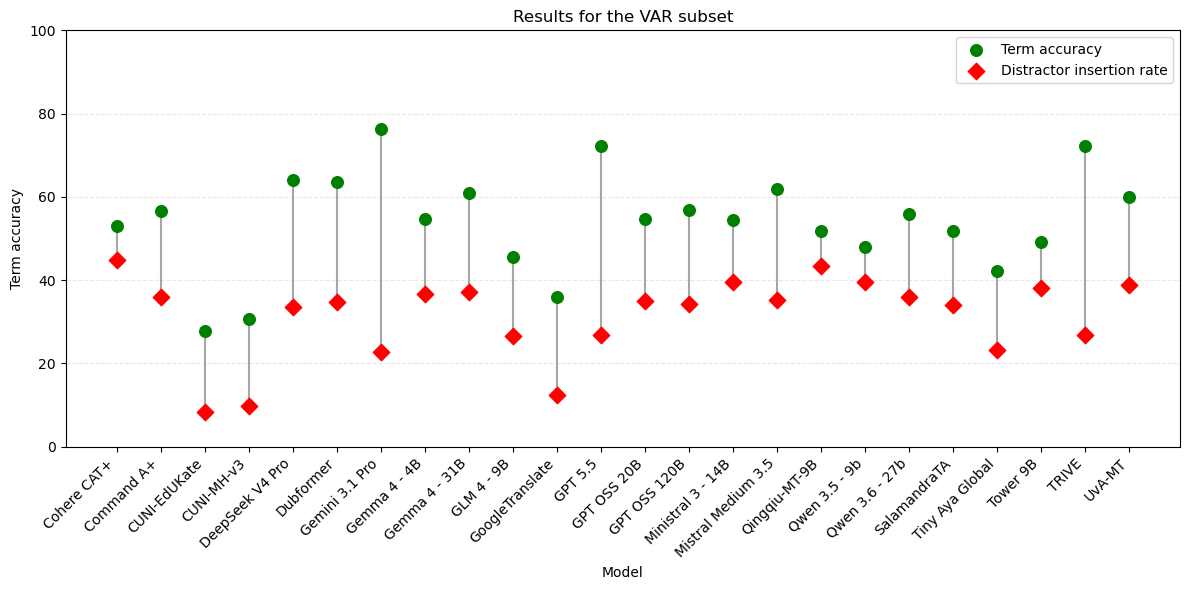

In [12]:
fig, ax, term_accuracy_df = plot_term_accuracy(
    var_matches_list_synth,
    var_distractors_matches_list_synth
)

plt.show()

In [13]:
fig.savefig("./results_tables_and_plots/2_ta_var.png", dpi=300, bbox_inches="tight")
term_accuracy_df

,model,term_accuracy,distractor_match_rate
0,Cohere CAT+,53.068592,44.765343
1,Command A+,56.618532,35.860409
2,CUNI-EdUKate,27.737665,8.363418
3,CUNI-MH-v3,30.565584,9.747292
4,DeepSeek V4 Pro,63.959085,33.513839
5,Dubformer,63.658243,34.777377
6,Gemini 3.1 Pro,76.353791,22.803851
7,Gemma 4 - 4B,54.632972,36.762936
8,Gemma 4 - 31B,60.950662,37.063779
9,GLM 4 - 9B,45.487365,26.594465


## plot blue here by par and synth

In [14]:
#!pip install sacrebleu

### define a function for bleu scoring

In [15]:
from sacrebleu.metrics import BLEU, CHRF

In [16]:
def score_corpus(hypotheses, references, metric='chrf', n_bootstrap=1000):
    """
    Compute corpus-level BLEU or chrF for every model.

    Parameters
    ----------
    hypotheses : str, Path, or pd.DataFrame
        Either:
          - a directory containing one .txt file per model (filename = model name), or
          - a DataFrame with one column per model, one row per segment.
    references : str, Path, or list[str]
        Either:
          - a path to a TSV with a 'context' column holding reference sentences, or
          - a list of reference sentences (one per segment).
    metric : str
        'bleu' or 'chrf'.
    n_bootstrap : int
        Bootstrap resamples for confidence intervals.

    Returns
    -------
    scores : dict[str, float]
        model_name -> corpus score.
    results_df : pd.DataFrame
        New DataFrame with columns ['model', metric], one row per model.
    """
    assert metric in ('bleu', 'chrf'), "metric must be 'bleu' or 'chrf'"

    # --- load reference ---
    if isinstance(references, (list, tuple, pd.Series)):
        references = [str(r) for r in references]
    else:
        reference_path = Path(references)
        if not reference_path.exists():
            raise FileNotFoundError(f"Reference file not found: {reference_path}")

        references_df = pd.read_csv(reference_path, sep='\t', encoding='utf-8')
        if 'context' not in references_df.columns:
            raise ValueError(
                f"Column 'context' not found in {reference_path}. "
                f"Available columns: {list(references_df.columns)}"
            )
        references = references_df['context'].astype(str).tolist()

    # --- init scorer ---
    if metric == 'bleu':
        scorer = BLEU(tokenize='13a')
        decimals = 2
    else:
        scorer = CHRF(word_order=2)
        decimals = 4

    # --- build model_name -> list[str] mapping from either input type ---
    model_hyps = {}

    if isinstance(hypotheses, pd.DataFrame):
        for model_name in hypotheses.columns:
            model_hyps[model_name] = hypotheses[model_name].astype(str).tolist()

    else:
        hypotheses_dir = Path(hypotheses)
        if not hypotheses_dir.is_dir():
            raise NotADirectoryError(f"Hypotheses directory not found: {hypotheses_dir}")

        hypothesis_files = sorted(hypotheses_dir.glob('*.txt'))
        if not hypothesis_files:
            raise FileNotFoundError(f"No .txt files found in: {hypotheses_dir}")

        for hyp_file in hypothesis_files:
            with open(hyp_file, encoding='utf-8') as f:
                model_hyps[hyp_file.stem] = [line.rstrip('\n') for line in f]

    if not model_hyps:
        raise ValueError("No models found in `hypotheses` (empty directory or empty DataFrame).")

    # --- score each model ---
    print(f"{'='*60}\nScoring with {metric.upper()}\n{'='*60}")

    scores = {}
    for model_name, hyps in model_hyps.items():
        if len(hyps) != len(references):
            raise ValueError(
                f"Length mismatch for '{model_name}': "
                f"{len(hyps)} hypotheses vs {len(references)} references"
            )

        result = scorer.corpus_score(hyps, [references], n_bootstrap=n_bootstrap)
        score = round(result.score, decimals)
        scores[model_name] = score

        #print(f"  {model_name}:")
        #print(f"    Result details: {result}")
        #print(f"    Signature:      {scorer.get_signature()}")

    # --- build results DataFrame from scratch ---
    results_df = pd.DataFrame(
        {'model': list(scores.keys()), metric: list(scores.values())}
    )

    return scores, results_df

In [17]:
# reference_context_german
df_var = pd.read_csv('../df_var.tsv', sep='\t', encoding='utf-8')
references = df_var['reference_context_german'].astype(str).tolist()

references_par = [references[i] for i in par_idx]
references_synth = [r for i, r in enumerate(references) if i not in set(par_idx)]

In [18]:
bleu_scores_synth, bleu_scores_synth_df = score_corpus(
    hypotheses=hyp_translations_var_synth,
    references=references_synth,
    metric='bleu',
)

Scoring with BLEU


In [19]:
bleu_scores_synth_df.columns = ['model', 'ST']
bleu_scores_synth_df.to_csv("./results_tables_and_plots/bleu_var.tsv", sep="\t", index=False)
bleu_scores_synth_df

,model,ST
0,Cohere CAT+,35.22
1,Command A+,32.69
2,CUNI-EdUKate,26.62
3,CUNI-MH-v3,29.05
4,DeepSeek V4 Pro,44.26
5,Dubformer,42.60
6,Gemini 3.1 Pro,48.39
7,Gemma 4 - 31B,37.98
8,Gemma 4 - 4B,31.39
9,GLM 4 - 9B,24.54


### for parallel validation

In [20]:
def compare_parallel_contexts_bleu(
    var_testset,
    hyp_translations,
    references,
    n_bootstrap=1000
):
    """
    Compare BLEU scores between paired synthetic and parallel contexts.

    Returns
    -------
    pandas.DataFrame
        Fresh dataframe with columns:
        model, synthetic_bleu, parallel_bleu
    """

    if len(var_testset) != len(hyp_translations):
        raise ValueError(
            f"Length mismatch: test set = {len(var_testset)}, "
            f"hypotheses = {len(hyp_translations)}"
        )

    if len(var_testset) != len(references):
        raise ValueError(
            f"Length mismatch: test set = {len(var_testset)}, "
            f"references = {len(references)}"
        )

    testset = var_testset.reset_index(drop=True).copy()
    hypotheses = hyp_translations.reset_index(drop=True).copy()
    references = pd.Series(references).reset_index(drop=True)

    # Identify paired synthetic / parallel examples
    testset["base_id"] = testset["instance_id"].str.replace(
        r"_par$", "", regex=True
    )
    testset["is_par"] = testset["instance_id"].str.endswith("_par")

    paired_base_ids = (
        testset
        .groupby("base_id")["is_par"]
        .nunique()
    )

    paired_base_ids = paired_base_ids[
        paired_base_ids == 2
    ].index

    paired_mask = testset["base_id"].isin(paired_base_ids)

    synthetic_mask = paired_mask & (~testset["is_par"])
    parallel_mask = paired_mask & testset["is_par"]

    # Synthetic subset
    synthetic_hypotheses = hypotheses.loc[
        synthetic_mask
    ].reset_index(drop=True)

    synthetic_references = references.loc[
        synthetic_mask
    ].astype(str).tolist()

    # Parallel subset
    parallel_hypotheses = hypotheses.loc[
        parallel_mask
    ].reset_index(drop=True)

    parallel_references = references.loc[
        parallel_mask
    ].astype(str).tolist()

    # BLEU
    _, synthetic_df = score_corpus(
        hypotheses=synthetic_hypotheses,
        references=synthetic_references,
        metric="bleu",
        n_bootstrap=n_bootstrap
    )

    _, parallel_df = score_corpus(
        hypotheses=parallel_hypotheses,
        references=parallel_references,
        metric="bleu",
        n_bootstrap=n_bootstrap
    )

    # Fresh result dataframe
    bleu_results_df = (
        synthetic_df
        .rename(columns={"bleu": "synthetic_bleu"})
        .merge(
            parallel_df.rename(
                columns={"bleu": "parallel_bleu"}
            ),
            on="model"
        )
    )

    return bleu_results_df

def plot_parallel_bleu_results(results, figsize=(12, 6)):
    """
    Plot synthetic vs parallel BLEU scores by model.
    """

    x = np.arange(len(results))

    fig, ax = plt.subplots(figsize=figsize)

    # Vertical connector
    for i in x:
        ax.plot(
            [i, i],
            [
                results.loc[i, "synthetic_bleu"],
                results.loc[i, "parallel_bleu"]
            ],
            color="gray",
            linewidth=1.5,
            alpha=0.7,
            zorder=1
        )

    # Synthetic BLEU
    ax.scatter(
        x,
        results["synthetic_bleu"],
        marker="o",
        color="tab:blue",
        s=70,
        label="Synthetic source",
        zorder=2
    )

    # Parallel BLEU
    ax.scatter(
        x,
        results["parallel_bleu"],
        marker="D",
        color="tab:orange",
        s=70,
        label="Parallel source",
        zorder=2
    )

    ax.set_xticks(x)
    ax.set_xticklabels(
        results["model"],
        rotation=45,
        ha="right"
    )

    ax.set_xlabel("Model")
    ax.set_ylabel("BLEU score")

    ax.legend()
    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.3
    )

    fig.tight_layout()

    return fig, ax

In [21]:
bleu_parallel_validation = compare_parallel_contexts_bleu(
    var_testset=var_testset,
    hyp_translations=hyp_translations_var,
    references=references
)

Scoring with BLEU
Scoring with BLEU


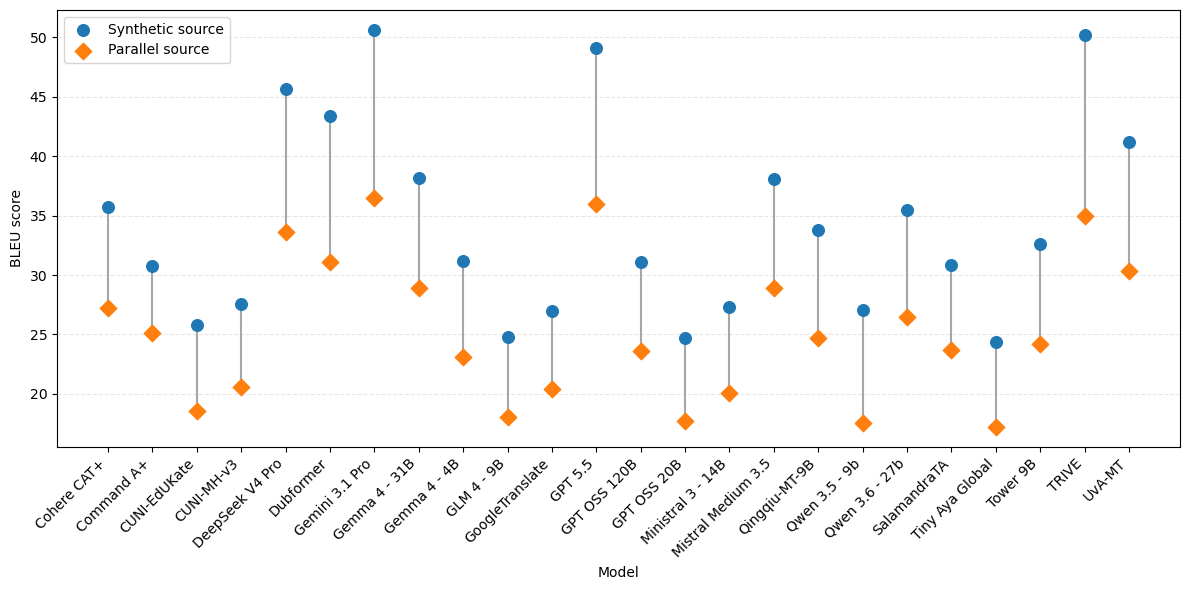

In [22]:
fig, ax = plot_parallel_bleu_results(
    bleu_parallel_validation
)

In [23]:
fig.savefig("./results_tables_and_plots/1_synth_validation_bleu_var.png", dpi=300, bbox_inches="tight")
bleu_parallel_validation.to_csv("./results_tables_and_plots/1_synth_validation_bleu_var.tsv", sep="\t", index=False)
bleu_parallel_validation

,model,synthetic_bleu,parallel_bleu
0,Cohere CAT+,35.75,27.22
1,Command A+,30.80,25.15
2,CUNI-EdUKate,25.80,18.58
3,CUNI-MH-v3,27.56,20.54
4,DeepSeek V4 Pro,45.65,33.66
5,Dubformer,43.40,31.11
6,Gemini 3.1 Pro,50.64,36.49
7,Gemma 4 - 31B,38.20,28.93
8,Gemma 4 - 4B,31.17,23.07
9,GLM 4 - 9B,24.77,18.07


# percentages of per variety distractor match

### very big models mistake towards Austria, other models towards germany

In [24]:
var_matches_AT = pd.read_csv(
    "./wmt_json_translations/results/var/tgt_term_AT.csv",
    sep=",",
    encoding="utf-8-sig"
)[cols]

var_matches_DE = pd.read_csv(
    "./wmt_json_translations/results/var/tgt_term_DE.csv",
    sep=",",
    encoding="utf-8-sig"
)[cols]

var_matches_CH = pd.read_csv(
    "./wmt_json_translations/results/var/tgt_term_CH.csv",
    sep=",",
    encoding="utf-8-sig"
)[cols]


var_matches_AT_bin = var_matches_AT.map(
    lambda x: 0 if str(x).strip() in ["[]", "", "nan"] else 1
)

var_matches_DE_bin = var_matches_DE.map(
    lambda x: 0 if str(x).strip() in ["[]", "", "nan"] else 1
)

var_matches_CH_bin = var_matches_CH.map(
    lambda x: 0 if str(x).strip() in ["[]", "", "nan"] else 1
)

In [25]:
import pandas as pd
import numpy as np


def match_rate_distractor_var(matches_df):
    """
    Calculate match rate (%) for each model.

    Rules
    -----
    []                  -> 0
    non-empty term/list -> 1
    None / NaN / ""     -> excluded

    Returns
    -------
    pandas.DataFrame
        One row per model with:
        model, match_rate, n_evaluated, n_matches
    """

    results = []

    for model in matches_df.columns:

        col = matches_df[model]

        # Exclude actual NaN / None and empty strings
        valid_mask = (
            col.notna()
            & (col.astype(str).str.strip() != "")
            & (col.astype(str).str.strip().str.lower() != "nan")
        )

        valid = col.loc[valid_mask]

        # [] = 0, anything else = 1
        binary = valid.apply(
            lambda x: 0 if str(x).strip() == "[]" else 1
        )

        results.append({
            "model": model,
            "match_rate": binary.mean() * 100,
            "n_evaluated": len(binary),
            "n_matches": binary.sum()
        })

    return pd.DataFrame(results)

In [26]:
var_CH_accuracy = match_rate_distractor_var(
    var_matches_CH_synth
)

rel_DE_accuracy = match_rate_distractor_var(
    var_matches_DE_synth
)

rel_AT_accuracy = match_rate_distractor_var(
    var_matches_AT_synth
)

var_distractor_rates = (
    rel_AT_accuracy[["model", "match_rate"]]
    .rename(columns={"match_rate": "AT"})
    .merge(
        rel_DE_accuracy[["model", "match_rate"]]
        .rename(columns={"match_rate": "DE"}),
        on="model"
    )
    .merge(
        var_CH_accuracy[["model", "match_rate"]]
        .rename(columns={"match_rate": "CH"}),
        on="model"
    )
)

mean_row = {
    "model": "Mean",
    "AT": var_distractor_rates["AT"].mean(),
    "DE": var_distractor_rates["DE"].mean(),
    "CH": var_distractor_rates["CH"].mean()
}

var_distractor_rates = pd.concat(
    [var_distractor_rates, pd.DataFrame([mean_row])],
    ignore_index=True
)

var_distractor_rates.to_csv("./results_tables_and_plots/3_distractor_varieties.tsv", sep="\t", index=False)
var_distractor_rates

,model,AT,DE,CH
0,Cohere CAT+,44.970414,47.073579,36.842105
1,Command A+,35.108481,36.872910,30.263158
2,CUNI-EdUKate,7.396450,8.361204,7.675439
3,CUNI-MH-v3,8.382643,10.618729,7.565789
4,DeepSeek V4 Pro,36.094675,33.862876,26.315789
5,Dubformer,35.009862,36.036789,28.618421
6,Gemini 3.1 Pro,24.950690,23.996656,19.956140
7,Gemma 4 - 4B,33.530572,36.538462,33.004386
8,Gemma 4 - 31B,35.305720,36.204013,31.030702
9,GLM 4 - 9B,23.372781,24.581940,23.245614


### collect accuracy rates and bleu/chrf for each model in a table

###  for var subset you can directly use the tsv of results. For rel and hom, it depends on data visualization. For variety-invariant results, yes. otherwise, attach result of the matcher and the testset, then groupby variety. 
### Bleu

### display in a plot the results of the correct term selection together with the bleu

### repeat for the main results of each subset (call the function on the subset data every time)

# Analysis by domain

In [27]:
# Count each individual legal domain without exploding the dataframe
domain_counts = (
    var_testset_synth["legal_domain"]
    .dropna()
    .str.split("|")
    .apply(lambda x: [d.strip() for d in x])
    .sum()
)

domain_counts = pd.Series(domain_counts).value_counts()

domain_counts

diritto civile/Zivilrecht                                     199
sicurezza sul lavoro/Arbeitsschutz                            189
diritto penale/Strafrecht                                     174
diritto processuale penale/Strafprozessrecht                  131
diritto amministrativo/Verwaltungsrecht                       130
legislazione stradale/Straßenverkehrsrecht                    112
diritto processuale civile/Zivilprozessrecht                  110
diritto societario/Gesellschaftsrecht                          92
diritto commerciale/Handelsrecht                               89
diritto delle obbligazioni/Schuldrecht                         88
diritto di famiglia/Familienrecht                              76
diritto del lavoro/Arbeitsrecht                                75
diritto delle obbligazioni PS/Schuldrecht BT                   58
diritto costituzionale/Verfassungsrecht                        58
diritto pubblico/öffentliches Recht                            51
diritto de

In [28]:
def term_accuracy_by_domain(
    var_testset,
    var_matches,
    domain_column="domain",
    min_instances=20,
    decimals=2
):
    """
    Create a wide terminology-accuracy table.

    Rows:
        models

    Columns:
        legal domains with more than min_instances,
        plus one 'Other' column for all remaining domains.

    Cells:
        terminology accuracy (%) for that model/domain.

    Pipe-delimited domain labels are treated as multi-label.
    """

    if len(var_testset) != len(var_matches):
        raise ValueError(
            f"Length mismatch: test set = {len(var_testset)}, "
            f"matches = {len(var_matches)}"
        )

    # --------------------------------------------------------
    # Parse domain labels row by row
    # --------------------------------------------------------

    parsed_domains = (
        var_testset[domain_column]
        .fillna("")
        .apply(
            lambda x: [
                d.strip()
                for d in str(x).split("|")
                if d.strip()
            ]
        )
    )

    # --------------------------------------------------------
    # Count instances per individual domain
    # --------------------------------------------------------

    domain_counts = (
        parsed_domains
        .explode()
        .value_counts()
    )

    # Keep domains with MORE than min_instances
    main_domains = domain_counts[
        domain_counts > min_instances
    ].index.tolist()

    # Remaining domains are grouped as Other
    other_domains = set(
        domain_counts[
            domain_counts <= min_instances
        ].index
    )

    results = []

    # --------------------------------------------------------
    # Main domains
    # --------------------------------------------------------

    for domain in main_domains:

        domain_mask = parsed_domains.apply(
            lambda domains: domain in domains
        )

        domain_accuracy = (
            var_matches.loc[domain_mask].mean() * 100
        )

        for model, accuracy in domain_accuracy.items():
            results.append({
                "model": model,
                "domain": domain,
                "term_accuracy": accuracy
            })

    # --------------------------------------------------------
    # Other
    # --------------------------------------------------------

    # A row belongs to Other if it contains at least one
    # domain whose frequency is <= min_instances
    other_mask = parsed_domains.apply(
        lambda domains:
        any(domain in other_domains for domain in domains)
    )

    other_accuracy = (
        var_matches.loc[other_mask].mean() * 100
    )

    for model, accuracy in other_accuracy.items():
        results.append({
            "model": model,
            "domain": "Other",
            "term_accuracy": accuracy
        })

    # --------------------------------------------------------
    # Wide paper-style table
    # --------------------------------------------------------

    long_df = pd.DataFrame(results)

    table_df = long_df.pivot(
        index="model",
        columns="domain",
        values="term_accuracy"
    )

    # Keep main domains first, Other last
    column_order = [
        d for d in main_domains
        if d in table_df.columns
    ]

    if "Other" in table_df.columns:
        column_order.append("Other")

    table_df = table_df[column_order].round(decimals)

    table_df.index.name = None
    table_df.columns.name = None

    return table_df, domain_counts

In [29]:
domain_accuracy_table, domain_counts = term_accuracy_by_domain(
    var_testset=var_testset_synth,
    var_matches=var_matches_list_synth,
    domain_column="legal_domain",
    min_instances=20,
    decimals=2
)



In [30]:
domain_mapping = {
    "diritto civile/Zivilrecht": "Civil Law",
    "sicurezza sul lavoro/Arbeitsschutz": "Occupational Health and Safety Law",
    "diritto penale/Strafrecht": "Criminal Law",
    "diritto processuale penale/Strafprozessrecht": "Criminal Procedure Law",
    "diritto amministrativo/Verwaltungsrecht": "Administrative Law",
    "legislazione stradale/Straßenverkehrsrecht": "Road Traffic Law",
    "diritto processuale civile/Zivilprozessrecht": "Civil Procedure Law",
    "diritto societario/Gesellschaftsrecht": "Company Law",
    "diritto commerciale/Handelsrecht": "Commercial Law",
    "diritto delle obbligazioni/Schuldrecht": "Law of Obligations",
    "diritto di famiglia/Familienrecht": "Family Law",
    "diritto del lavoro/Arbeitsrecht": "Employment Law",
    "diritto delle obbligazioni PS/Schuldrecht BT": "Law of Obligations – Special Part",
    "diritto costituzionale/Verfassungsrecht": "Constitutional Law",
    "diritto pubblico/öffentliches Recht": "Public Law",
    "diritto delle successioni/Erbrecht": "Law of Succession",
    "juris": "juris",
    "diritto sanitario/Gesundheitsrecht": "Health Law",
    "diritto delle assicurazioni/Versicherungsrecht": "Insurance Law",
    "diritto ambientale/Umweltrecht": "Environmental Law",
    "diritto dei trasporti/Transportrecht": "Transport Law",
}

domain_accuracy_table = domain_accuracy_table.rename(columns=domain_mapping)

In [31]:
domain_accuracy_table.loc["Mean"] = (
    domain_accuracy_table.mean(axis=0).round(2)
)
domain_accuracy_table

,Civil Law,Occupational Health and Safety Law,Criminal Law,Criminal Procedure Law,Administrative Law,Road Traffic Law,Civil Procedure Law,Company Law,Commercial Law,Law of Obligations,Family Law,Employment Law,Law of Obligations – Special Part,Constitutional Law,Public Law,Law of Succession,juris,Health Law,Insurance Law,Other
CUNI-EdUKate,28.64,30.16,25.86,20.61,34.62,22.32,16.36,28.26,25.84,30.68,30.26,29.33,31.03,41.38,41.18,15.56,35.29,43.75,28.57,20.78
CUNI-MH-v3,35.68,32.80,29.89,20.61,30.77,25.89,12.73,36.96,29.21,27.27,36.84,30.67,39.66,44.83,47.06,28.89,35.29,46.88,28.57,35.06
Cohere CAT+,57.79,50.79,65.52,49.62,60.77,54.46,48.18,52.17,51.69,59.09,57.89,48.00,65.52,63.79,60.78,55.56,64.71,53.12,42.86,54.55
Command A+,58.29,60.32,65.52,58.02,56.92,57.14,56.36,57.61,56.18,57.95,55.26,44.00,67.24,68.97,62.75,51.11,64.71,59.38,46.43,62.34
DeepSeek V4 Pro,69.35,56.61,70.69,60.31,73.08,56.25,60.00,65.22,68.54,77.27,57.89,62.67,77.59,65.52,70.59,73.33,73.53,56.25,50.00,67.53
Dubformer,69.85,64.02,72.99,61.07,72.31,58.04,62.73,61.96,62.92,70.45,61.84,62.67,72.41,68.97,64.71,62.22,73.53,53.12,67.86,67.53
GLM 4 - 9B,55.28,45.50,48.85,45.04,56.15,42.86,38.18,50.00,40.45,53.41,48.68,40.00,51.72,50.00,58.82,40.00,38.24,40.62,32.14,44.16
GPT 5.5,75.88,69.84,78.16,67.94,80.00,64.29,68.18,71.74,67.42,81.82,68.42,76.00,82.76,81.03,80.39,77.78,76.47,65.62,64.29,75.32
GPT OSS 120B,62.81,48.15,65.52,51.91,57.69,56.25,57.27,58.70,55.06,67.05,50.00,50.67,58.62,72.41,72.55,62.22,64.71,53.12,53.57,64.94
GPT OSS 20B,56.78,47.62,58.05,49.62,58.46,54.46,54.55,58.70,50.56,60.23,59.21,53.33,62.07,77.59,66.67,66.67,61.76,56.25,35.71,53.25


In [32]:
domain_accuracy_table = domain_accuracy_table.loc[model_order + ["Mean"]].rename_axis("model")
domain_accuracy_table.to_csv("./results_tables_and_plots/4_domain_var.tsv", sep="\t", index=True)


# Analysis by distractor number

In [33]:
def term_accuracy_by_distractor_count(
    var_testset,
    var_matches,
    distractor_column="N distractor",
    decimals=2
):
    """
    Create a wide terminology-accuracy table by number of distractors.

    Values 8 and above are grouped into a single "8+" category.
    A final Mean row is added across models.
    """

    if len(var_testset) != len(var_matches):
        raise ValueError(
            f"Length mismatch: test set = {len(var_testset)}, "
            f"matches = {len(var_matches)}"
        )

    # Create grouped distractor categories
    distractor_groups = var_testset[distractor_column].apply(
        lambda x: "8+" if pd.notna(x) and x >= 8 else x
    )

    results = []

    # Keep numeric groups in order, then 8+
    group_values = sorted(
        [x for x in distractor_groups.dropna().unique() if x != "8+"]
    )

    if "8+" in distractor_groups.values:
        group_values.append("8+")

    for value in group_values:

        mask = distractor_groups == value

        group_matches = var_matches.loc[mask]

        group_accuracy = group_matches.mean() * 100

        for model, accuracy in group_accuracy.items():
            results.append({
                "model": model,
                "n_distractors": value,
                "term_accuracy": accuracy
            })

    long_df = pd.DataFrame(results)

    table_df = long_df.pivot(
        index="model",
        columns="n_distractors",
        values="term_accuracy"
    )

    table_df = table_df[group_values].round(decimals)

    table_df.index.name = None
    table_df.columns.name = None

    # Add mean across models for each distractor group
    table_df.loc["Mean"] = table_df.mean(axis=0).round(decimals)

    return table_df

In [34]:
distractor_accuracy_table = term_accuracy_by_distractor_count(
    var_testset=var_testset_synth,
    var_matches=var_matches_list_synth,
    distractor_column="n_distractors",  # change if your exact column name differs
    decimals=2
)

distractor_accuracy_table

,1,2,3,4,5,6,7,8+
CUNI-EdUKate,32.70,27.38,26.11,24.81,21.92,28.57,16.67,4.35
CUNI-MH-v3,36.49,31.67,25.82,24.06,32.88,32.65,25.00,8.70
Cohere CAT+,75.22,58.82,41.84,42.86,39.73,30.61,12.50,4.35
Command A+,75.73,58.82,48.07,45.86,43.84,40.82,16.67,13.04
DeepSeek V4 Pro,81.58,66.06,53.71,51.88,57.53,51.02,29.17,43.48
Dubformer,82.27,64.71,55.79,51.13,53.42,53.06,45.83,30.43
GLM 4 - 9B,58.35,46.15,40.36,44.36,41.10,30.61,20.83,13.04
GPT 5.5,88.98,73.53,60.83,60.15,68.49,67.35,41.67,52.17
GPT OSS 120B,73.32,59.73,49.85,44.36,45.21,28.57,29.17,13.04
GPT OSS 20B,69.36,61.54,46.88,36.84,32.88,42.86,37.50,17.39


In [35]:
distractor_accuracy_table = distractor_accuracy_table.loc[model_order + ["Mean"]].rename_axis("model")
distractor_accuracy_table.to_csv("./results_tables_and_plots/5_distractor_number_var.tsv", sep="\t", index=True)

In [36]:
var_testset_synth["n_distractors"].value_counts()

n_distractors
1     581
2     442
3     337
4     133
5      73
6      49
7      24
8       8
10      5
9       4
11      3
12      2
13      1
Name: count, dtype: int64

# corpus frequency correlation (var subset only)

In [37]:
# Our test set does not reflect a realistic distribution. In real life, some terms are more frequenct than others. 
# This test set does not provide information whether most frequent terms are translated better or worse.
# We count term frequencies in a st corpus, then a pearson correlation to assess whether there is a correlation.


In [38]:
from scipy.stats import pointbiserialr
import pandas as pd


def pointbiserial_by_model(var_matches, freq_list):
    """
    Calculate point-biserial correlation between binary term match
    and term frequency for each model.

    Parameters
    ----------
    var_matches : pandas.DataFrame
        Binary match matrix.
        Rows = instances, columns = models.
        1 = match, 0 = no match.

    freq_list : pandas.Series
        Frequency value corresponding row-by-row to var_matches.

    Returns
    -------
    pandas.DataFrame
        One row per model with:
        model, point_biserial_r, p_value, n
    """


    freq = pd.Series(freq_list).reset_index(drop=True)

    results = []

    for model in var_matches.columns:

        matches = var_matches[model].reset_index(drop=True)

        # Keep only rows where both variables are available
        valid = matches.notna() & freq.notna()

        x = matches.loc[valid]
        y = freq.loc[valid]

        r, p = pointbiserialr(x, y)

        results.append({
            "model": model,
            "point_biserial_r": r,
            "p_value": p,
            "n": len(x)
        })

    return pd.DataFrame(results)

In [39]:
freq_correlation = pointbiserial_by_model(
    var_matches=var_matches_list_synth,
    freq_list=freq_count_list
)

freq_correlation

,model,point_biserial_r,p_value,n
0,Cohere CAT+,0.061372,1.233328e-02,1662
1,Command A+,0.064561,8.469454e-03,1662
2,CUNI-EdUKate,0.159353,6.432105e-11,1662
3,CUNI-MH-v3,0.140983,7.830878e-09,1662
4,DeepSeek V4 Pro,0.082402,7.723705e-04,1662
5,Dubformer,0.066746,6.487321e-03,1662
6,Gemini 3.1 Pro,0.060743,1.325720e-02,1662
7,Gemma 4 - 4B,0.040025,1.028622e-01,1662
8,Gemma 4 - 31B,0.069461,4.610690e-03,1662
9,GLM 4 - 9B,0.070178,4.204862e-03,1662


In [40]:
freq_correlation.to_csv("./results_tables_and_plots/6_frequency_correlation_var.tsv", sep="\t", index=False)

# variety overlapping (var subset only)

In [41]:
unique_st_ids = ['1001', '10175', '10191', '10734', '10770', '10831', '10883', '11322', '11555', '11675', '11750', '12292', '1243', '12485', '1256', '12608', '12653', '12661', '12681', '12688', '12717', '1274', '1276', '12774', '12818', '12819', '12906', '13130', '13246', '1331', '1337', '1369', '13861', '13916', '1419', '14490', '14548', '14620', '14692', '14730', '14796', '14820', '14850', '14865', '14891', '14921', '14922', '14923', '14931', '14932', '14957', '1497', '15010', '15074', '15189', '15227', '15236', '15260', '1530', '1535', '15400', '15452', '15537', '1557', '15750', '16042', '1620', '16359', '16379', '16380', '167', '16708', '16797', '16819', '16839', '16921', '16933', '17031', '17032', '1705', '1715', '17276', '17319', '17329', '17334', '17336', '17492', '17509', '1759', '17643', '17653', '1766', '17676', '17711', '17859', '17868', '1787', '17894', '17920', '17921', '17931', '17935', '1800', '18006', '1806', '1807', '18076', '18094', '18134', '18144', '1824', '18278', '1906', '19506', '19626', '1973', '19832', '19840', '19848', '2005', '2029', '20557', '20605', '2075', '21027', '2106', '2143', '2148', '21536', '21791', '21815', '2203', '22083', '22741', '228', '22857', '22883', '22887', '22900', '22931', '2300', '23023', '23130', '23176', '23321', '23354', '23381', '23401', '23457', '23461', '23465', '23547', '2355', '23567', '23575', '2385', '23872', '24048', '24103', '24107', '24137', '24138', '24143', '2419', '24213', '24361', '24410', '24496', '24618', '24640', '24644', '2473', '24758', '24876', '24910', '24928', '24938', '24986', '25084', '25091', '25097', '25115', '25199', '25211', '25212', '25308', '25446', '2560', '25697', '25716', '25734', '25799', '25849', '25892', '25938', '26262', '26283', '26423', '26523', '26678', '26773', '26789', '2703', '27030', '27180', '27195', '2723', '27317', '27375', '27538', '27630', '27648', '27651', '2766', '27661', '27754', '2779', '2787', '28048', '28049', '28052', '2824', '28240', '28292', '2836', '2838', '28423', '28490', '28585', '28602', '28730', '28808', '28809', '2894', '2952', '2953', '2977', '3001', '3046', '3052', '3057', '3103', '3209', '338', '3470', '3497', '3500', '3616', '3680', '3712', '3766', '3800', '3827', '3863', '3867', '3873', '3894', '3896', '3898', '3902', '3909', '3913', '3936', '3981', '3982', '4095', '4221', '4236', '4489', '4585', '4701', '48', '4915', '5007', '5089', '5090', '5118', '5199', '5209', '5232', '5249', '525', '5323', '5523', '5612', '5704', '5736', '5748', '5839', '587', '5933', '608', '6098', '6099', '6116', '63', '6362', '6371', '6449', '6481', '6551', '6668', '6675', '6680', '6693', '6725', '6727', '6835', '6901', '6931', '6957', '6991', '7036', '7163', '7242', '7253', '7346', '7376', '7491', '7687', '8048', '8139', '828', '829', '8548', '8605', '861', '878', '8961', '9085', '9205', '9518', '9831', '9837', '9962', '9963', '999']

In [42]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


def compare_unique_vs_nonunique_accuracy(
    var_testset,
    var_matches,
    concept_id_column,
    unique_concept_ids,
    figsize=(8, 5)
):
    """
    Compare descriptor/term match accuracy between:

    1. Rows whose concept IDs are in unique_concept_ids
    2. All remaining rows

    The same row masks are applied to var_testset and var_matches
    to preserve alignment.

    Returns
    -------
    unique_testset : pandas.DataFrame
        Test-set rows belonging to unique concept IDs.

    unique_matches : pandas.DataFrame
        Match rows corresponding to unique concept IDs.

    nonunique_testset : pandas.DataFrame
        Remaining test-set rows.

    nonunique_matches : pandas.DataFrame
        Match rows corresponding to remaining concept IDs.

    accuracy_df : pandas.DataFrame
        One row per model with unique and non-unique accuracy rates.

    fig, ax
        Matplotlib figure and axes.
    """

    # --------------------------------------------------------
    # Check original alignment
    # --------------------------------------------------------

    if len(var_testset) != len(var_matches):
        raise ValueError(
            f"Length mismatch before filtering: "
            f"test set = {len(var_testset)}, "
            f"matches = {len(var_matches)}"
        )

    # --------------------------------------------------------
    # Prepare concept IDs
    # --------------------------------------------------------

    unique_concept_ids = {str(x) for x in unique_concept_ids}

    concept_ids = var_testset[concept_id_column].astype(str)

    # Unique population
    unique_mask = concept_ids.isin(unique_concept_ids)

    # Remaining / non-unique population
    nonunique_mask = ~unique_mask

    # --------------------------------------------------------
    # Apply identical masks
    # --------------------------------------------------------

    unique_testset = var_testset.loc[unique_mask].copy()
    unique_matches = var_matches.loc[unique_mask].copy()

    nonunique_testset = var_testset.loc[nonunique_mask].copy()
    nonunique_matches = var_matches.loc[nonunique_mask].copy()

    # --------------------------------------------------------
    # Alignment checks
    # --------------------------------------------------------

    if len(unique_testset) != len(unique_matches):
        raise ValueError(
            "Length mismatch in unique subset: "
            f"test set = {len(unique_testset)}, "
            f"matches = {len(unique_matches)}"
        )

    if len(nonunique_testset) != len(nonunique_matches):
        raise ValueError(
            "Length mismatch in non-unique subset: "
            f"test set = {len(nonunique_testset)}, "
            f"matches = {len(nonunique_matches)}"
        )

    # --------------------------------------------------------
    # Calculate accuracy / match rates
    # --------------------------------------------------------

    unique_accuracy = unique_matches.mean() * 100
    nonunique_accuracy = nonunique_matches.mean() * 100

    accuracy_df = pd.DataFrame({
        "model": unique_accuracy.index,
        "unique_term_accuracy": unique_accuracy.values,
        "nonunique_term_accuracy": nonunique_accuracy.values
    })

    # --------------------------------------------------------
    # Length information
    # --------------------------------------------------------

    print(f"Original test-set rows:  {len(var_testset)}")
    print(f"Original match rows:     {len(var_matches)}")
    print()
    print(f"Unique test-set rows:    {len(unique_testset)}")
    print(f"Unique match rows:       {len(unique_matches)}")
    print()
    print(f"Non-unique test-set rows:{len(nonunique_testset)}")
    print(f"Non-unique match rows:   {len(nonunique_matches)}")

    # --------------------------------------------------------
    # Plot
    # --------------------------------------------------------

    x = np.arange(len(accuracy_df))

    fig, ax = plt.subplots(figsize=figsize)

    # Vertical connector between both scores
    for i in x:
        ax.plot(
            [i, i],
            [
                accuracy_df.loc[i, "unique_term_accuracy"],
                accuracy_df.loc[i, "nonunique_term_accuracy"]
            ],
            color="gray",
            linewidth=1.5,
            alpha=0.7,
            zorder=1
        )

    # Unique concept IDs
    ax.scatter(
        x,
        accuracy_df["unique_term_accuracy"],
        marker="o",
        color="tab:blue",
        s=70,
        label="Unique South Tyrolean terms",
        zorder=2
    )

    # Remaining concept IDs
    ax.scatter(
        x,
        accuracy_df["nonunique_term_accuracy"],
        marker="D",
        color="tab:orange",
        s=70,
        label="Terms shared with other varieties",
        zorder=2
    )

    ax.set_xticks(x)
    ax.set_xticklabels(
        accuracy_df["model"],
        rotation=45,
        ha="right"
    )

    ax.set_xlabel("Model")
    ax.set_ylabel("Term accuracy")
    ax.set_ylim(0, 100)

    ax.legend()
    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.3
    )

    fig.tight_layout()

    return (
        unique_testset,
        unique_matches,
        nonunique_testset,
        nonunique_matches,
        accuracy_df,
        fig,
        ax
    )

Original test-set rows:  1662
Original match rows:     1662

Unique test-set rows:    363
Unique match rows:       363

Non-unique test-set rows:1299
Non-unique match rows:   1299


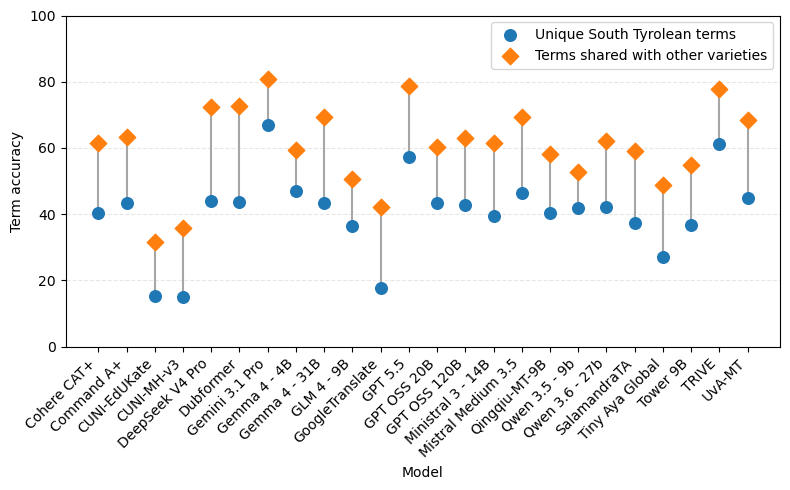

,model,unique_term_accuracy,nonunique_term_accuracy
0,Cohere CAT+,40.220386,61.354888
1,Command A+,43.526171,63.433410
2,CUNI-EdUKate,15.426997,31.639723
3,CUNI-MH-v3,15.151515,35.719784
4,DeepSeek V4 Pro,44.077135,72.363356
5,Dubformer,43.801653,72.671286
6,Gemini 3.1 Pro,66.942149,80.677444
7,Gemma 4 - 4B,47.107438,59.353349
8,Gemma 4 - 31B,43.526171,69.284065
9,GLM 4 - 9B,36.363636,50.731332


In [43]:
(
    unique_testset,
    unique_matches,
    nonunique_testset,
    nonunique_matches,
    unique_vs_nonunique_accuracy_df,
    fig,
    ax
) = compare_unique_vs_nonunique_accuracy(
    var_testset=var_testset_synth,
    var_matches=var_matches_list_synth,
    concept_id_column="concept_id",
    unique_concept_ids=unique_st_ids
)

plt.show()

unique_vs_nonunique_accuracy_df

In [68]:
unique_vs_nonunique_accuracy_df.to_csv("./results_tables_and_plots/3_distractor_rel.tsv", sep="\t", index=False)
fig.savefig("./results_tables_and_plots/7_unique_terms_var.png", dpi=300, bbox_inches="tight")
